In [2]:
library(dplyr)
## visualization
library(ggplot2)
library(ggplot2)
library(gridExtra)
library(dplyr)
library(ggplot2)
library(cowplot)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




In [3]:
setwd("/home/liuxuan/metadata/10-10/PRJNA747639/")
initial_meta <- read.csv("SraRunTable.csv", header = TRUE)
head(initial_meta)
colnames(initial_meta)

,Run,age_mths,age_wks,Assay.Type,AvgSpotLen,Bases,BioProject,BioSample,BioSampleModel,breast_milk_ever,⋯,Organism,Platform,ReleaseDate,create_date,version,Sample.Name,SRA.Study,total_breastfed_wks,treatmentgroup,wave
,<chr>,<dbl>,<int>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<int>,<chr>,<chr>
1,SRR15179339,18.30,74,AMPLICON,281,7623693,PRJNA747639,SAMN20291641,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",no,⋯,human saliva metagenome,ION_TORRENT,2022-07-04T00:00:00Z,2021-07-18T04:45:00Z,1,654B4,SRP328745,0,NB,Wave 4
2,SRR15179340,10.25,41,AMPLICON,281,7762283,PRJNA747639,SAMN20291640,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",no,⋯,human saliva metagenome,ION_TORRENT,2022-07-04T00:00:00Z,2021-07-18T04:45:00Z,1,654B3,SRP328745,0,NB,Wave 3
3,SRR15179341,12.71,51,AMPLICON,277,18802439,PRJNA747639,SAMN20291552,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",yes,⋯,human saliva metagenome,ION_TORRENT,2022-07-04T00:00:00Z,2021-07-18T04:45:00Z,1,022B3,SRP328745,40,B10,Wave 3
4,SRR15179342,17.12,69,AMPLICON,275,21567347,PRJNA747639,SAMN20291638,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",no,⋯,human saliva metagenome,ION_TORRENT,2022-07-04T00:00:00Z,2021-07-18T04:45:00Z,1,630B4,SRP328745,0,NB,Wave 4
5,SRR15179343,11.93,48,AMPLICON,279,19195994,PRJNA747639,SAMN20291637,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",no,⋯,human saliva metagenome,ION_TORRENT,2022-07-04T00:00:00Z,2021-07-18T04:45:00Z,1,630B3,SRP328745,0,NB,Wave 3
6,SRR15179344,9.56,39,AMPLICON,269,8159023,PRJNA747639,SAMN20291636,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",no,⋯,human saliva metagenome,ION_TORRENT,2022-07-04T00:00:00Z,2021-07-18T04:45:00Z,1,630B2,SRP328745,0,NB,Wave 2


[1] "Run"                            "age_mths"                      
 [3] "age_wks"                        "Assay.Type"                    
 [5] "AvgSpotLen"                     "Bases"                         
 [7] "BioProject"                     "BioSample"                     
 [9] "BioSampleModel"                 "breast_milk_ever"              
[11] "breastfed_wks"                  "Bytes"                         
[13] "Center.Name"                    "Collection_Date"               
[15] "Consent"                        "current_breast_milk"           
[17] "DATASTORE.filetype"             "DATASTORE.provider"            
[19] "DATASTORE.region"               "drink_formula"                 
[21] "env_broad_scale"                "env_local_scale"               
[23] "env_medium"                     "exclusive_breastfeed"          
[25] "Experiment"                     "geo_loc_name_country"          
[27] "geo_loc_name_country_continent" "geo_loc_name"                  
[29] "HOST"                           "id"                            
[31] "Instrument"                     "lat_lon"                       
[33] "Library.Name"                   "LibraryLayout"                 
[35] "LibrarySelection"               "LibrarySource"                 
[37] "Organism"                       "Platform"                      
[39] "ReleaseDate"                    "create_date"                   
[41] "version"                        "Sample.Name"                   
[43] "SRA.Study"                      "total_breastfed_wks"           
[45] "treatmentgroup"                 "wave"

In [5]:
uniform_meta <- data.frame(
    BioProject = initial_meta$BioProject,
    Run = initial_meta$Run,
    sample_name = initial_meta$`Sample.Name`,
    Age = initial_meta$age_mths,
    BMI = NA,
    Sex = NA,
    Region = "V4",
    Platform = initial_meta$Platform,
    Country = initial_meta$geo_loc_name_country,
    Site = 'saliva',
    public_time = initial_meta$ReleaseDate,
    PCR_primers = NA,
    title = 'Breastmilk influences development and composition of the oral microbiome',
    Disease_study = "NO",
    Status = NA,
    matched_samples = 'NO')
print(length(unique(uniform_meta$Run)))
print(length(unique(uniform_meta$sample_name)))

[1] 149
[1] 149


In [6]:
uniform_meta

BioProject,Run,sample_name,Age,BMI,Sex,Region,Platform,Country,Site,public_time,PCR_primers,title,Disease_study,Status,matched_samples
<chr>,<chr>,<chr>,<dbl>,<lgl>,<lgl>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<chr>,<chr>,<lgl>,<chr>
PRJNA747639,SRR15179339,654B4,18.30,NA,NA,V4,ION_TORRENT,Australia,saliva,2022-07-04T00:00:00Z,NA,Breastmilk influences development and composition of the oral microbiome,NO,NA,NO
PRJNA747639,SRR15179340,654B3,10.25,NA,NA,V4,ION_TORRENT,Australia,saliva,2022-07-04T00:00:00Z,NA,Breastmilk influences development and composition of the oral microbiome,NO,NA,NO
PRJNA747639,SRR15179341,022B3,12.71,NA,NA,V4,ION_TORRENT,Australia,saliva,2022-07-04T00:00:00Z,NA,Breastmilk influences development and composition of the oral microbiome,NO,NA,NO
PRJNA747639,SRR15179342,630B4,17.12,NA,NA,V4,ION_TORRENT,Australia,saliva,2022-07-04T00:00:00Z,NA,Breastmilk influences development and composition of the oral microbiome,NO,NA,NO
PRJNA747639,SRR15179343,630B3,11.93,NA,NA,V4,ION_TORRENT,Australia,saliva,2022-07-04T00:00:00Z,NA,Breastmilk influences development and composition of the oral microbiome,NO,NA,NO
PRJNA747639,SRR15179344,630B2,9.56,NA,NA,V4,ION_TORRENT,Australia,saliva,2022-07-04T00:00:00Z,NA,Breastmilk influences development and composition of the oral microbiome,NO,NA,NO
PRJNA747639,SRR15179345,654B1,2.17,NA,NA,V4,ION_TORRENT,Australia,saliva,2022-07-04T00:00:00Z,NA,Breastmilk influences development and composition of the oral microbiome,NO,NA,NO
PRJNA747639,SRR15179346,630B1,2.50,NA,NA,V4,ION_TORRENT,Australia,saliva,2022-07-04T00:00:00Z,NA,Breastmilk influences development and composition of the oral microbiome,NO,NA,NO
PRJNA747639,SRR15179347,627B4,17.28,NA,NA,V4,ION_TORRENT,Australia,saliva,2022-07-04T00:00:00Z,NA,Breastmilk influences development and composition of the oral microbiome,NO,NA,NO


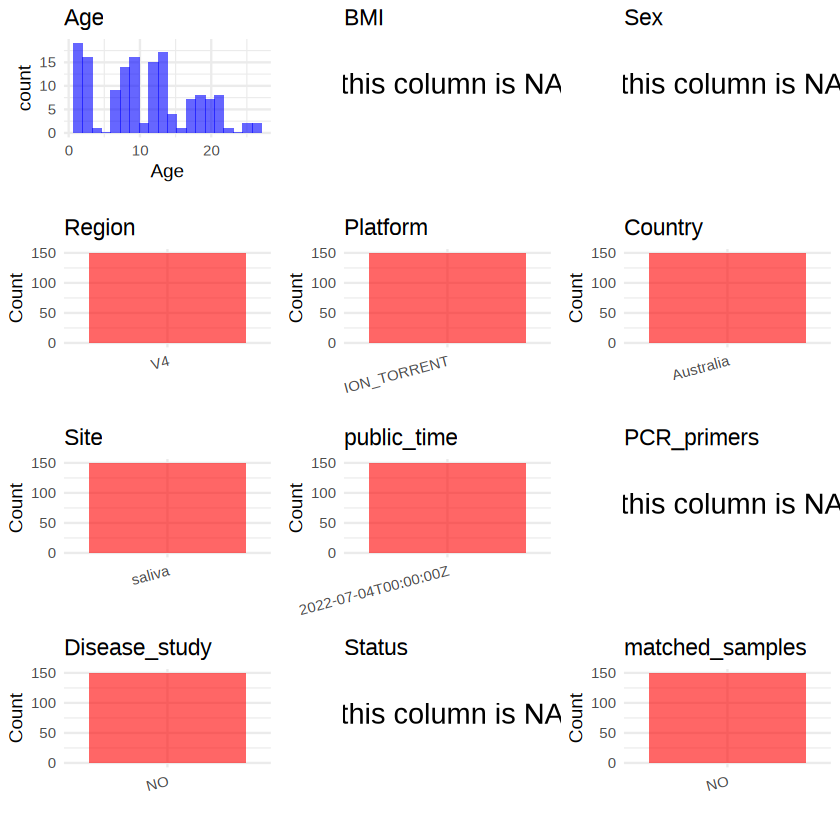

In [8]:
plot_data <- uniform_meta %>%
  select(-BioProject, -Run, -sample_name, -title)

create_simple_plots <- function(data) {
  plots <- list()
  
  for (col in colnames(data)) {
    if (all(is.na(data[[col]]))) {
      p <- ggplot() +
        annotate("text", x = 0.5, y = 0.5, label = "this column is NA", size = 6) +
        labs(title = col) +
        theme_void()
    } else if (is.numeric(data[[col]])) {
      p <- ggplot(data, aes(x = .data[[col]])) +
        geom_histogram(fill = "blue", alpha = 0.6, bins = 20, na.rm = TRUE) +
        labs(title = col) +
        theme_minimal()
    } else {
      count_data <- as.data.frame(table(data[[col]], useNA = "ifany"))
      p <- ggplot(count_data, aes(x = reorder(Var1, -Freq), y = Freq)) +
        geom_col(fill = "red", alpha = 0.6) +
        labs(title = col, x = NULL, y = "Count") +
        theme_minimal() +
        theme(axis.text.x = element_text(angle = 15, hjust = 1))
    }
    plots[[col]] <- p
  }
  return(plots)
}

plots <- create_simple_plots(plot_data)
p<-plot_grid(plots$Age, 
          plots$BMI, 
          plots$Sex, 
          plots$Region, 
          plots$Platform, 
          plots$Country, 
          plots$Site,
          plots$public_time, 
          plots$PCR_primers,
          plots$Disease_study,
          plots$Status,
          plots$matched_samples,# add 
          ncol = 3, align = "hv", axis = "lb")
p

In [9]:
uniform_meta <- uniform_meta[, c("BioProject", "Run", "sample_name", "Age", "BMI", "Sex", "Region", "Platform", "Country", "Site", "public_time", "PCR_primers", "title", "Disease_study", "Status")]
write.csv(uniform_meta, file = "/home/liuxuan/metadata/10-10/PRJNA747639/metadata.csv", quote = T)